# Quantium Virtual Internship — Task 1
## Data preparation and customer segmentation

This notebook uses **QVI_transaction_data.xlsx** for purchase records and **QVI Purchase Behaviour.csv** for customer information. The files are joined using the loyalty card number so we can study sales by customer group. One exact duplicate transaction is removed. Customer 226000 is excluded because their two purchases of 200 units each are unusually large bulk purchases and could distort typical shopping patterns. Run the cells from top to bottom.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE_DIR = Path.cwd()
transaction_file = "QVI_transaction_data.xlsx"
behaviour_file = "QVI Purchase Behaviour.csv"

# Check the current folder and its parent for both data files.
while not (
    (BASE_DIR / transaction_file).is_file()
    and (BASE_DIR / behaviour_file).is_file()
) and BASE_DIR.parent != BASE_DIR:
    BASE_DIR = BASE_DIR.parent

TRANSACTION_PATH = BASE_DIR / transaction_file
BEHAVIOUR_PATH = BASE_DIR / behaviour_file

if not TRANSACTION_PATH.is_file() or not BEHAVIOUR_PATH.is_file():
    raise FileNotFoundError(
        "Could not find both data files. Put the notebook and data files in the project folder."
    )


print(f"Transaction data: {TRANSACTION_PATH.name}")
print(f"Customer data: {BEHAVIOUR_PATH.name}")

Transaction data: QVI_transaction_data.xlsx
Customer data: QVI Purchase Behaviour.csv


## 1. Load, clean, and combine the data

The transaction file stores dates as Excel numbers, so we convert them to calendar dates. We remove exact duplicate rows and exclude the two bulk purchases from customer 226000. Then we join each transaction to the customer's life stage and customer type using the loyalty card number. The join is checked to make sure it does not duplicate transactions and that every transaction has a matching customer record.

**Business purpose:** these steps make sure the customer-group sales comparison is based on clean transactions with customer information attached.

In [2]:
raw_transactions = pd.read_excel(TRANSACTION_PATH)
customer_data = pd.read_csv(BEHAVIOUR_PATH, sep=";")

transaction_columns = {
    "DATE", "STORE_NBR", "LYLTY_CARD_NBR", "TXN_ID",
    "PROD_NBR", "PROD_NAME", "PROD_QTY", "TOT_SALES",
}
customer_columns = {"LYLTY_CARD_NBR", "LIFESTAGE", "PREMIUM_CUSTOMER"}
if not transaction_columns.issubset(raw_transactions.columns):
    raise ValueError(f"Transaction data is missing columns: {sorted(transaction_columns - set(raw_transactions.columns))}")
if not customer_columns.issubset(customer_data.columns):
    raise ValueError(f"Customer data is missing columns: {sorted(customer_columns - set(customer_data.columns))}")
if customer_data["LYLTY_CARD_NBR"].duplicated().any():
    raise ValueError("Customer data must have one row per loyalty card.")

transaction_data = raw_transactions.copy()
transaction_data["DATE"] = pd.to_datetime(
    transaction_data["DATE"], unit="D", origin="1899-12-30", errors="raise"
)
exact_duplicates = int(transaction_data.duplicated().sum())
transaction_data = transaction_data.drop_duplicates().copy()
bulk_customer_id = 226000
bulk_customer_rows = int((transaction_data["LYLTY_CARD_NBR"] == bulk_customer_id).sum())
transaction_data = transaction_data.loc[
    transaction_data["LYLTY_CARD_NBR"] != bulk_customer_id
].copy()

if transaction_data[["TOT_SALES", "PROD_QTY", "LYLTY_CARD_NBR"]].isna().any().any():
    raise ValueError("Required transaction fields contain missing values.")
if (transaction_data["TOT_SALES"] < 0).any() or (transaction_data["PROD_QTY"] <= 0).any():
    raise ValueError("Unexpected negative sales or non-positive product quantity found.")

data = transaction_data.merge(
    customer_data, on="LYLTY_CARD_NBR", how="left", validate="many_to_one", indicator=True
)
unmatched_rows = int(data["_merge"].ne("both").sum())
if unmatched_rows:
    raise ValueError(f"{unmatched_rows:,} transactions have no customer segment.")
data = data.drop(columns="_merge")
data["PACK_SIZE"] = pd.to_numeric(
    data["PROD_NAME"].str.extract(r"(\d+)\s*g\b", expand=False), errors="coerce"
)
data["BRAND"] = data["PROD_NAME"].str.strip().str.split().str[0].str.upper()

print(f"Raw transaction rows: {len(raw_transactions):,}")
print(f"Exact duplicate rows removed: {exact_duplicates:,}")
print(f"Bulk-customer rows removed (card {bulk_customer_id}): {bulk_customer_rows:,}")
print(f"Clean transaction rows: {len(transaction_data):,}")
print(f"Customer cards matched: {data['LYLTY_CARD_NBR'].nunique():,}")
print(f"Unmatched transactions: {unmatched_rows:,}")
print(f"Date range: {data['DATE'].min():%Y-%m-%d} to {data['DATE'].max():%Y-%m-%d}")
print(f"Clean sales total: ${data['TOT_SALES'].sum():,.2f}")
display(data.head())

Raw transaction rows: 264,836
Exact duplicate rows removed: 1
Bulk-customer rows removed (card 226000): 2
Clean transaction rows: 264,833
Customer cards matched: 72,636
Unmatched transactions: 0
Date range: 2018-07-01 to 2019-06-30
Clean sales total: $1,933,109.00


,DATE,STORE_NBR,LYLTY_CARD_NBR,TXN_ID,PROD_NBR,PROD_NAME,PROD_QTY,TOT_SALES,LIFESTAGE,PREMIUM_CUSTOMER,PACK_SIZE,BRAND
0,2018-10-17,1,1000,1,5,Natural Chip Compny SeaSalt175g,2,6.0,YOUNG SINGLES/COUPLES,Premium,175.0,NATURAL
1,2019-05-14,1,1307,348,66,CCs Nacho Cheese 175g,3,6.3,MIDAGE SINGLES/COUPLES,Budget,175.0,CCS
2,2019-05-20,1,1343,383,61,Smiths Crinkle Cut Chips Chicken 170g,2,2.9,MIDAGE SINGLES/COUPLES,Budget,170.0,SMITHS
3,2018-08-17,2,2373,974,69,Smiths Chip Thinly S/Cream&Onion 175g,5,15.0,MIDAGE SINGLES/COUPLES,Budget,175.0,SMITHS
4,2018-08-18,2,2426,1038,108,Kettle Tortilla ChpsHny&Jlpno Chili 150g,3,13.8,MIDAGE SINGLES/COUPLES,Budget,150.0,KETTLE


## 2. Check transactions and monthly sales

This section checks how many products were bought per transaction and displays total sales for each month after cleaning.

**Business purpose:** checking unusual purchase sizes helps us understand why bulk purchases were excluded. The monthly chart also confirms that the cleaned data covers the expected period and shows how sales change over time.

Product quantities per transaction:


,transaction_rows
PROD_QTY,
1,27518
2,236038
3,430
4,397
5,450


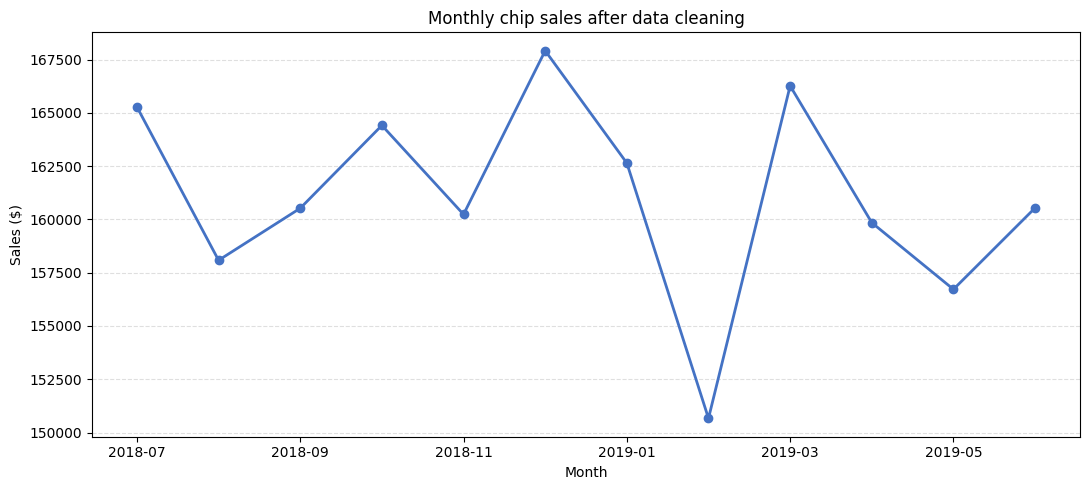

Months covered: 12
Transactions per month (sales range): $150,665.00–$167,913.40


In [3]:
print("Product quantities per transaction:")
display(data["PROD_QTY"].value_counts().sort_index().rename("transaction_rows").to_frame())

monthly_sales = data.groupby(data["DATE"].dt.to_period("M"))["TOT_SALES"].sum()
monthly_sales.index = monthly_sales.index.astype(str)
fig, ax = plt.subplots(figsize=(11, 5))
monthly_sales.plot(ax=ax, marker="o", color="#4472C4", linewidth=2)
ax.set(title="Monthly chip sales after data cleaning", xlabel="Month", ylabel="Sales ($)")
ax.grid(axis="y", linestyle="--", alpha=0.4)
fig.tight_layout()
plt.show()

print(f"Months covered: {len(monthly_sales)}")
print(f"Transactions per month (sales range): ${monthly_sales.min():,.2f}–${monthly_sales.max():,.2f}")

## 3. Customer segment performance

The table compares total sales, number of customers, number of transactions, and average sales per customer for each life-stage and customer-type group. A customer is counted once within each group.

**Business purpose:** a group can have high sales because it has many customers, because each customer spends more, or both. Reading sales together with customer count and sales per customer helps distinguish these explanations. The final check confirms that segment sales add up to the cleaned transaction sales.

In [4]:
segment_summary = (
    data.groupby(["LIFESTAGE", "PREMIUM_CUSTOMER"], as_index=False)
    .agg(
        total_sales=("TOT_SALES", "sum"),
        customers=("LYLTY_CARD_NBR", "nunique"),
        transactions=("TXN_ID", "nunique"),
        units=("PROD_QTY", "sum"),
    )
)
segment_summary["sales_per_customer"] = segment_summary["total_sales"] / segment_summary["customers"]
segment_summary["transactions_per_customer"] = segment_summary["transactions"] / segment_summary["customers"]
segment_summary["customer_share_pct"] = 100 * segment_summary["customers"] / data["LYLTY_CARD_NBR"].nunique()
segment_summary = segment_summary.sort_values("total_sales", ascending=False).reset_index(drop=True)

assert int(segment_summary["customers"].sum()) == data["LYLTY_CARD_NBR"].nunique()
assert np.isclose(segment_summary["total_sales"].sum(), data["TOT_SALES"].sum())

print("Top 10 life-stage / premium-customer segments by sales:")
print(segment_summary.head(10).round(2).to_string(index=False))
print(f"\nSegment sales reconcile to transaction sales: ${segment_summary['total_sales'].sum():,.2f}")

Top 10 life-stage / premium-customer segments by sales:
            LIFESTAGE PREMIUM_CUSTOMER  total_sales  customers  transactions  units  sales_per_customer  transactions_per_customer  customer_share_pct
       OLDER FAMILIES           Budget    168363.25       4675         22935  45065               36.01                       4.91                6.44
YOUNG SINGLES/COUPLES       Mainstream    157621.60       8088         20783  38632               19.49                       2.57               11.13
             RETIREES       Mainstream    155677.05       6479         21363  40518               24.03                       3.30                8.92
       YOUNG FAMILIES           Budget    139345.85       4017         18970  37111               34.69                       4.72                5.53
OLDER SINGLES/COUPLES           Budget    136769.80       4929         18301  35220               27.75                       3.71                6.79
OLDER SINGLES/COUPLES       Mainstream

## 4. Life-stage summary and chart

This section summarizes sales and customer counts by life stage, then creates a chart of the ten highest-selling customer groups. The customer count is based on unique loyalty cards.

**How to read the chart:** longer bars mean higher total sales; they do not necessarily mean higher spending per customer. Use the table above to compare both measures.

,LIFESTAGE,total_sales,customers,transactions,customer_share_pct,sales_per_customer
0,OLDER SINGLES/COUPLES,402420.75,14609,54147,20.11,27.55
1,RETIREES,366470.90,14805,49512,20.38,24.75
2,OLDER FAMILIES,352467.20,9779,48124,13.46,36.04
3,YOUNG FAMILIES,316160.10,9178,43242,12.64,34.45
4,YOUNG SINGLES/COUPLES,260405.30,14441,36255,19.88,18.03
5,MIDAGE SINGLES/COUPLES,184751.30,7275,24949,10.02,25.40
6,NEW FAMILIES,50433.45,2549,6896,3.51,19.79


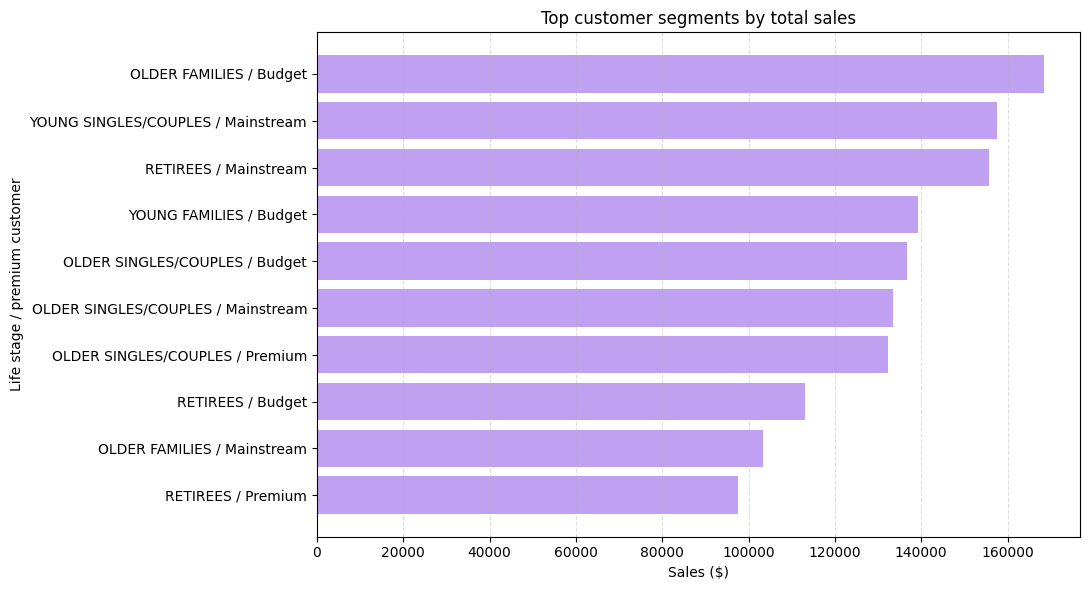

Largest segment by sales: OLDER FAMILIES / Budget
Largest life stage by customer count: RETIREES


In [5]:
life_stage_summary = (
    data.groupby("LIFESTAGE", as_index=False)
    .agg(
        total_sales=("TOT_SALES", "sum"),
        customers=("LYLTY_CARD_NBR", "nunique"),
        transactions=("TXN_ID", "nunique"),
    )
)
life_stage_summary["customer_share_pct"] = 100 * life_stage_summary["customers"] / data["LYLTY_CARD_NBR"].nunique()
life_stage_summary["sales_per_customer"] = life_stage_summary["total_sales"] / life_stage_summary["customers"]
life_stage_summary = life_stage_summary.sort_values("total_sales", ascending=False).reset_index(drop=True)
assert int(life_stage_summary["customers"].sum()) == data["LYLTY_CARD_NBR"].nunique()

display(life_stage_summary.round(2))

chart_data = segment_summary.head(10).sort_values("total_sales")
chart_labels = chart_data["LIFESTAGE"] + " / " + chart_data["PREMIUM_CUSTOMER"]
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(chart_labels, chart_data["total_sales"], color="#C0A1F1")
ax.set(title="Top customer segments by total sales", xlabel="Sales ($)", ylabel="Life stage / premium customer")
ax.grid(axis="x", linestyle="--", alpha=0.4)
fig.tight_layout()
fig.savefig(BASE_DIR / "task1_chart1_sales_by_segment.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Largest segment by sales: {segment_summary.iloc[0]['LIFESTAGE']} / {segment_summary.iloc[0]['PREMIUM_CUSTOMER']}")
print(f"Largest life stage by customer count: {life_stage_summary.sort_values('customers', ascending=False).iloc[0]['LIFESTAGE']}")

## Total sales & sales per customer

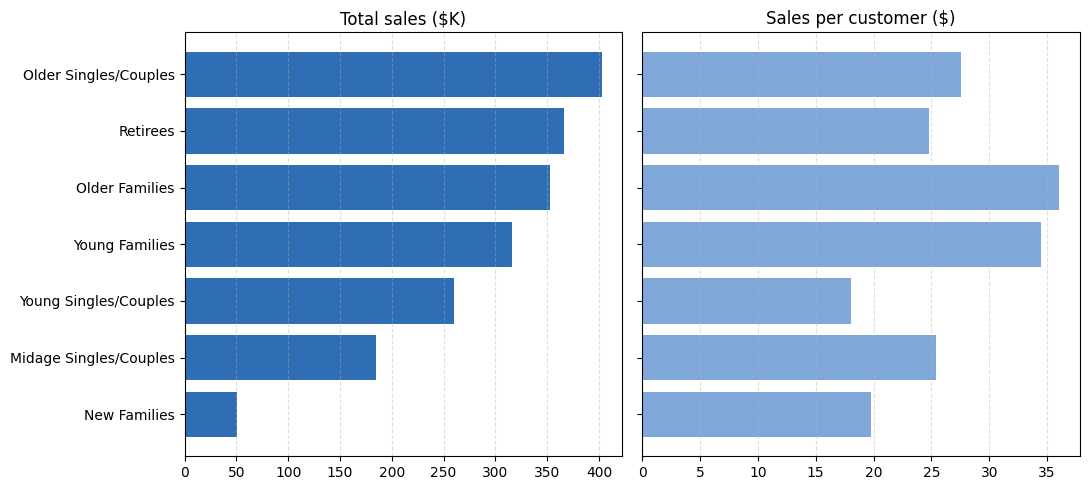

In [6]:
ls = life_stage_summary.sort_values("total_sales")
names = ls["LIFESTAGE"].str.title()

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
axes[0].barh(names, ls["total_sales"] / 1000, color="#2F6DB5")
axes[0].set_title("Total sales ($K)")

axes [1].barh(names, ls["sales_per_customer"], color ="#7FA8D9")
axes[1].set_title("Sales per customer ($)")

for ax in axes:
    ax.grid(axis="x", linestyle="--", alpha=0.4)

fig.tight_layout()
fig.savefig(BASE_DIR / "task1_chart2_lifestage_view.png", dpi=150, bbox_inches="tight")
plt.show()

## Customers vs Sales

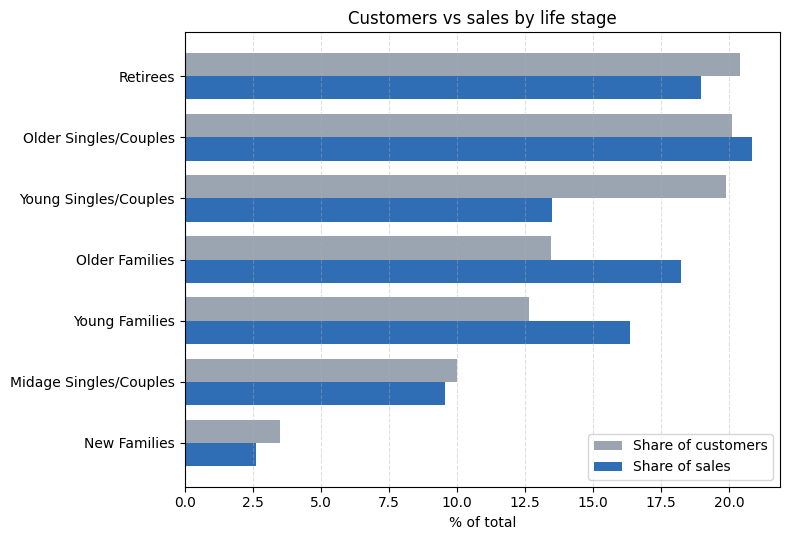

In [7]:
ls = life_stage_summary.copy()
ls["sales_share_pct"] = 100 * ls["total_sales"] / ls["total_sales"].sum()
ls = ls.sort_values("customer_share_pct")

y = np.arange(len(ls))
h = 0.38

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(y + h / 2, ls["customer_share_pct"], h, color="#9AA5B1", label="Share of customers")
ax.barh(y - h / 2, ls["sales_share_pct"], h, color="#2F6DB5", label="Share of sales")

ax.set_yticks(y)
ax.set_yticklabels(ls["LIFESTAGE"].str.title())
ax.set_xlabel("% of total")
ax.set_title("Customers vs sales by life stage")
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.legend()

fig.tight_layout()
fig.savefig(BASE_DIR / "task1_chart3_customers_vs_sales.png", dpi=150, bbox_inches="tight")
plt.show()

## Business summary: problem, action, and output

**Problem:** The business needs to understand which customer groups contribute most to chip sales. Raw transactions alone do not show each customer's life stage or customer type.

**Action:** We checked and cleaned the transaction data, removed one exact duplicate and two unusually large bulk purchases, and matched transactions to customer information using loyalty card numbers. We then compared sales, customer counts, and average sales per customer by group.

**Output:** The largest group by total sales is **Older Families / Budget**, with about **$168,363** in sales. **Older Singles/Couples** have the highest total sales among life stages, while **Retirees** have the largest number of unique customers. These findings show that the biggest sales group and the biggest customer group are not necessarily the same.

**Business interpretation:** Use these results to decide which groups may deserve closer attention in marketing or product planning. Compare total sales with sales per customer before prioritizing a group. This is a descriptive analysis: it shows what happened in the data, but it does not prove why customers behaved this way or that a specific action will cause sales to increase.